# 2. Treino

Transfer learning com MobileNetV2 (ImageNet). A lógica está em `src/models/train_model.py`. Por
padrão, este notebook mostra o modelo final (`models/notavelai.keras`) sem alterar nada.

In [1]:
import csv
import os
import sys
import warnings
from pathlib import Path

os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
warnings.filterwarnings("ignore")

# Permite importar src/ com o notebook aberto a partir de notebooks/ ou da raiz.
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)

from IPython.display import Image, Markdown, display
import json

import keras

from src.data.dataset import FIGURES_DIR, REPORTS_DIR
from src.models import ensemble, train_model

# True retreina com os dados atuais (cerca de 40 minutos) e SOBRESCREVE models/notavelai.keras
# e as curvas.
TREINAR = False

## Configuração

- **Preparo da imagem:** quadrado central da foto, reduzido a 224x224 (`smart_resize`), como no app
  e no artigo de Almeida et al. (2025). A nota ocupa a maior parte da imagem.
- **Fase 1:** base congelada, treina só a cabeça.
- **Fase 2:** ajuste fino da rede inteira (154 camadas), com learning rate baixo.
- **Entrada:** 224x224 RGB, float, valores 0–255. A normalização está dentro do grafo, então o app
  não deve normalizar.
- **Augmentations:** rodam no `tf.data` e não entram no modelo salvo.

In [2]:
for name in ("IMAGE_SIZE", "PREPROCESSING", "BATCH_SIZE", "HEAD_EPOCHS", "HEAD_LEARNING_RATE", "FINE_EPOCHS",
             "FINE_LEARNING_RATE", "FINE_TUNE_LAYERS", "PATIENCE", "DROPOUT", "SEED"):
    print(f"{name:20} {getattr(train_model, name)}")

IMAGE_SIZE           (224, 224)
PREPROCESSING        crop
BATCH_SIZE           32
HEAD_EPOCHS          30
HEAD_LEARNING_RATE   0.001
FINE_EPOCHS          30
FINE_LEARNING_RATE   2e-05
FINE_TUNE_LAYERS     154
PATIENCE             6
DROPOUT              0.3
SEED                 42


In [3]:
if TREINAR:
    train_model.main()
else:
    print("TREINAR = False: mostrando o modelo final")

TREINAR = False: mostrando o modelo final


## Arquitetura

In [4]:
model = keras.models.load_model(ensemble.MEMBERS["notavelai.tflite"])
model.summary()

Model: "notavelai"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagem_0_255 (InputLayer)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ normalizacao (Rescaling)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ classes (Dense)                 │ (None, 8)              │        10,248 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,668,250 (25.44 MB)

 Trainable params: 2,200,008 (8.39 MB)

 Non-trainable params: 68,224 (266.50 KB)

 Optimizer params: 4,400,018 (16.78 MB)

## Curvas de treino

A linha tracejada marca o início do ajuste fino. O modelo salvo é o de menor `val_loss`.

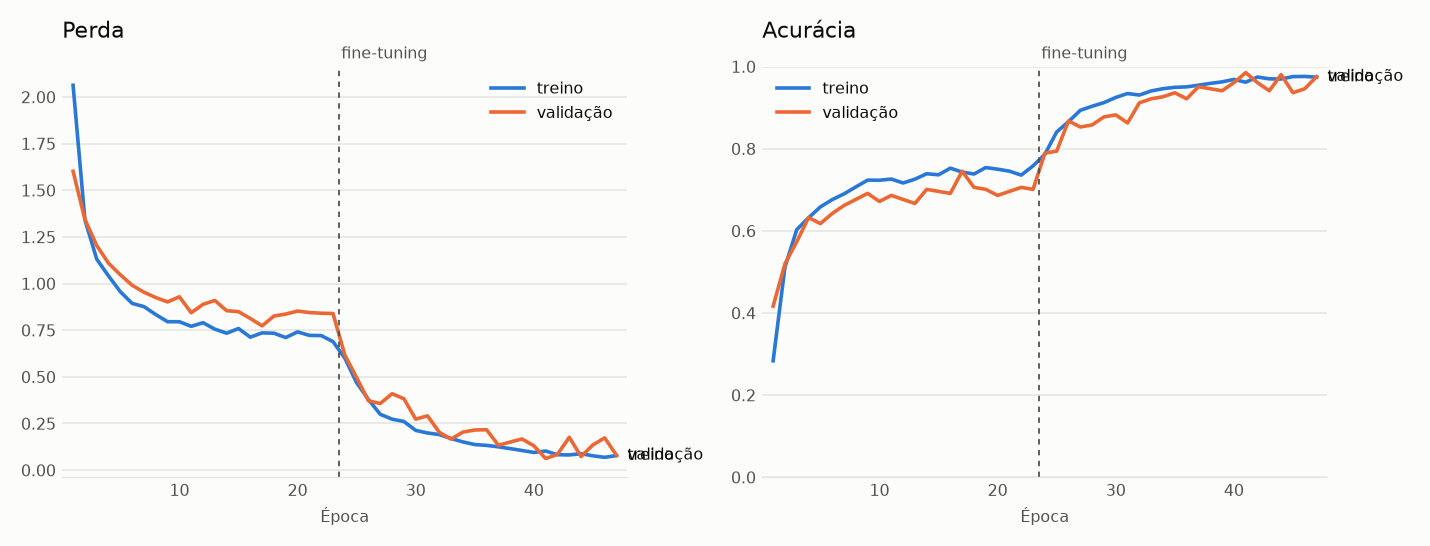

In [5]:
display(Image(FIGURES_DIR / "training_curves.png", width=900))

In [6]:
history = json.loads((REPORTS_DIR / "training_history.json").read_text())
for phase, label in (("head", "Fase 1"), ("fine_tuning", "Fase 2")):
    values = history[phase]
    best = min(range(len(values["val_loss"])), key=values["val_loss"].__getitem__)
    print(f"{label}: {len(values['loss'])} épocas; melhor val_loss {values['val_loss'][best]:.4f}, "
          f"acurácia de validação {values['val_accuracy'][best]:.4f}")

Fase 1: 23 épocas; melhor val_loss 0.7734, acurácia de validação 0.7451
Fase 2: 24 épocas; melhor val_loss 0.0621, acurácia de validação 0.9853
